# Chapter 13 : Processing Sequences Using RNNs and CNNs

In [3]:
import tarfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torchmetrics
from torch import nn
from torch.utils.data import DataLoader, Dataset

In [4]:
if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

device

'mps'

**Exercice 1 : Use the Seq2SeqModel to forecast both rail and bus ridership for the next 14 days.**

In [5]:
def download_and_extract_ridership_data():
    data_dir = Path("datasets")
    csv_path = data_dir / "ridership" / "CTA_-_Ridership_-_Daily_Boarding_Totals.csv"
    if csv_path.is_file():  # on teste le CSV, pas l'archive
        return csv_path
    data_dir.mkdir(parents=True, exist_ok=True)
    tarball_path = data_dir / "ridership.tgz"
    url = "https://github.com/ageron/data/raw/main/ridership.tgz"
    urllib.request.urlretrieve(url, tarball_path)
    with tarfile.open(tarball_path) as tar:
        tar.extractall(path=data_dir, filter="data")
    return csv_path


path = download_and_extract_ridership_data()

df = pd.read_csv(path, parse_dates=["service_date"], date_format="%m/%d/%Y")
df.columns = ["date", "day_type", "bus", "rail", "total"]
df = df.sort_values("date").set_index("date").drop(columns="total")
df = df[~df.index.duplicated(keep="first")]  # une seule ligne par date
df = df.asfreq("D")  # index quotidien, aucune ligne ajoutée ici

print(df.shape, df.index.min().date(), df.index.max().date())

(7639, 3) 2001-01-01 2021-11-30


In [ ]:
# Fonction d'entrainement et d'évaluation


def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            metric.update(y_pred, y_batch)
    return metric.compute()


def train(
    model,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    patience=10,
    factor=0.1,
):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=patience, factor=factor
    )
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": []}
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        scheduler.step(val_metric)
        print(
            f"Epoch {epoch + 1}/{n_epochs}, "
            f"train loss: {history['train_losses'][-1]:.4f}, "
            f"train metric: {history['train_metrics'][-1]:.4f}, "
            f"valid metric: {history['valid_metrics'][-1]:.4f}"
        )
    return history


def fit_and_evaluate(
    model,
    train_loader,
    valid_loader,
    lr,
    weight_decay=0.01,
    n_epochs=50,
    patience=20,
    factor=0.1,
):
    loss_fn = nn.HuberLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    metric = torchmetrics.MeanAbsoluteError().to(device)
    history = train(
        model,
        optimizer,
        loss_fn,
        metric,
        train_loader,
        valid_loader,
        n_epochs=n_epochs,
        patience=patience,
        factor=factor,
    )
    return min(history["valid_metrics"]) * 1e6

In [ ]:
# Classe personnalisée pour les datasets


class Seq2SeqDataset(Dataset):
    def __init__(self, series, window_length, window_target):
        self.series = series
        self.window_length = window_length
        self.window_target = window_target

    def __len__(self):
        return len(self.series) - self.window_length - self.window_target + 1

    def __getitem__(self, idx):
        end = idx + self.window_length
        window = self.series[idx:end]
        target_period = self.series[idx + 1 : end + self.window_target, :2]
        target = target_period.unfold(dimension=0, size=self.window_target, step=1)
        return window, target

In [42]:
df_mulvar = df[["rail", "bus"]] / 1e6  # use both rail & bus series as input
df_mulvar["next_day_type"] = df["day_type"].shift(-1)  # we know tomorrow's type
df_mulvar = pd.get_dummies(df_mulvar, dtype=float)  # one-hot encode day type

In [43]:
mulvar_train = torch.FloatTensor(df_mulvar["2016-01":"2018-12"].values)
mulvar_valid = torch.FloatTensor(df_mulvar["2019-01":"2019-05"].values)
mulvar_test = torch.FloatTensor(df_mulvar["2019-06":].values)

In [44]:
# Création des datasets et dataloaders

window_length = 56
window_target = 14
seq_train_set = Seq2SeqDataset(mulvar_train, window_length, window_target)
seq_train_loader = DataLoader(seq_train_set, batch_size=32, shuffle=True)
seq_valid_set = Seq2SeqDataset(mulvar_valid, window_length, window_target)
seq_valid_loader = DataLoader(seq_valid_set, batch_size=32)
seq_test_set = Seq2SeqDataset(mulvar_test, window_length, window_target)
seq_test_loader = DataLoader(seq_test_set, batch_size=32)

In [ ]:
class Seq2SeqRnnModel(nn.Module):
    def __init__(
        self,
        input_size,
        window_target,
        hidden_size=32,
        n_layers=2,
        rnn_type="rnn",
        dropout=0.0,
    ):
        super().__init__()
        rnn_class = {"rnn": nn.RNN, "gru": nn.GRU, "lstm": nn.LSTM}[rnn_type]
        self.window_target = window_target
        self.rnn = rnn_class(
            input_size,
            hidden_size,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0,
        )
        self.output = nn.Linear(hidden_size, window_target * 2)  # 2 variables prédites

    def forward(self, x):
        out, _ = self.rnn(x)
        out = self.output(out)
        return out.unflatten(-1, (2, self.window_target))

In [ ]:
def evaluate_per_variable(
    model, data_loader, names=("bus", "rail"), scale=1e6, last_step_only=True
):
    model.eval()
    abs_err, n = None, 0
    with torch.no_grad():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            pred = model(X)  # (B, L, 2, T)
            assert pred.shape == y.shape, (
                f"pred {tuple(pred.shape)} != y {tuple(y.shape)}"
            )
            assert y.shape[-2] == len(names), (
                f"{y.shape[-2]} variable(s) dans les cibles, {len(names)} noms donnés"
            )
            if last_step_only:
                pred, y = pred[:, -1], y[:, -1]  # (B, 2, T)
            err = (pred - y).abs().movedim(-2, 0).reshape(len(names), -1)  # (2, B*T)
            abs_err = err.sum(dim=1) if abs_err is None else abs_err + err.sum(dim=1)
            n += err.shape[1]
    mae = abs_err / n * scale
    return {name: mae[i].item() for i, name in enumerate(names)}

In [ ]:
import math
import optuna


def evaluate_tm(model, data_loader, metric):
    model.eval()
    metric.reset()
    with torch.no_grad():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            metric.update(
                model(X)[:, -1].contiguous(), y[:, -1].contiguous()
            )  # dernier pas seulement
    return metric.compute()


def train(
    model,
    optimizer,
    loss_fn,
    metric,
    train_loader,
    valid_loader,
    n_epochs,
    patience=10,
    factor=0.1,
    max_grad_norm=1.0,
    trial=None,
    verbose=True,
):
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="min", patience=patience, factor=factor
    )
    history = {"train_losses": [], "train_metrics": [], "valid_metrics": [], "lrs": []}
    best_metric, best_state = float("inf"), None

    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = loss_fn(y_pred, y_batch)
            if not math.isfinite(loss.item()):  # divergence
                if trial is not None:
                    raise optuna.TrialPruned()
                raise RuntimeError(
                    f"Perte non finie à l'epoch {epoch + 1} : learning rate trop élevé ?"
                )
            total_loss += loss.item()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred[:, -1].contiguous(), y_batch[:, -1].contiguous())

        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(metric.compute().item())
        val_metric = evaluate_tm(model, valid_loader, metric).item()
        history["valid_metrics"].append(val_metric)
        history["lrs"].append(optimizer.param_groups[0]["lr"])

        if val_metric < best_metric:  # meilleur epoch
            best_metric = val_metric
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        scheduler.step(val_metric)

        if trial is not None:  # pruning Optuna
            trial.report(val_metric, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if verbose:
            print(
                f"Epoch {epoch + 1}/{n_epochs}, "
                f"train loss: {history['train_losses'][-1]:.4f}, "
                f"train metric: {history['train_metrics'][-1]:.4f}, "
                f"valid metric: {val_metric:.4f}"
            )

    model.load_state_dict(best_state)  # le modèle final = le meilleur epoch
    return history

In [ ]:
SCALE = 1e6  # seulement si la série a été divisée par 1e6 (sinon voir plus bas)
N_EPOCHS_SEARCH = 20  # fixe pour tous les essais


def build_model(rnn_type, hidden_size, n_layers, dropout):
    torch.manual_seed(42)  # mêmes poids de départ pour des essais comparables
    n_features = seq_train_loader.dataset.series.shape[1]
    return Seq2SeqRnnModel(
        input_size=n_features,
        window_target=window_target,
        hidden_size=hidden_size,
        n_layers=n_layers,
        rnn_type=rnn_type,
        dropout=dropout,
    ).to(device)


def objective(trial):
    params = {
        "rnn_type": trial.suggest_categorical("rnn_type", ["rnn", "gru", "lstm"]),
        "hidden_size": trial.suggest_int("hidden_size", 16, 128, step=16),
        "n_layers": trial.suggest_int("n_layers", 1, 3),
        "dropout": trial.suggest_float(
            "dropout", 0.0, 0.3, step=0.1
        ),  # ignoré si n_layers == 1
    }
    lr = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    weight_decay = trial.suggest_float("weight_decay", 1e-6, 1e-1, log=True)

    model = build_model(**params)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    metric = torchmetrics.MeanAbsoluteError().to(device)

    history = train(
        model,
        optimizer,
        nn.HuberLoss(),
        metric,
        seq_train_loader,
        seq_valid_loader,
        n_epochs=N_EPOCHS_SEARCH,
        patience=5,
        factor=0.5,
        trial=trial,
        verbose=False,
    )
    return min(history["valid_metrics"]) * SCALE  # MAE de validation, en passagers

In [ ]:
Path("models/ch13").mkdir(parents=True, exist_ok=True)

sampler = optuna.samplers.TPESampler(seed=42)
pruner = optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=5)

study = optuna.create_study(
    study_name="seq2seq_rnn_v3",
    direction="minimize",  # on minimise une erreur
    sampler=sampler,
    pruner=pruner,
    storage="sqlite:///models/ch13/optuna.db",  # sauvegarde sur disque
    load_if_exists=True,  # permet de reprendre
)
study.optimize(objective, n_trials=30, gc_after_trial=True)

print("Meilleure MAE de validation :", study.best_value)
print("Meilleurs paramètres :", study.best_params)

[I 2026-11-14 19:40:06,153] A new study created in RDB with name: seq2seq_rnn_v3
[I 2026-11-14 19:40:17,781] Trial 0 finished with value: 124212.3395204544 and parameters: {'rnn_type': 'gru', 'hidden_size': 80, 'n_layers': 1, 'dropout': 0.0, 'lr': 0.00013066739238053285, 'weight_decay': 0.021423021757741075}. Best is trial 0 with value: 124212.3395204544.
[I 2026-11-14 19:40:53,530] Trial 1 finished with value: 38903.314620256424 and parameters: {'rnn_type': 'gru', 'hidden_size': 128, 'n_layers': 3, 'dropout': 0.0, 'lr': 0.0002310201887845295, 'weight_decay': 8.260808399079606e-06}. Best is trial 1 with value: 38903.314620256424.
[I 2026-11-14 19:41:17,436] Trial 2 finished with value: 62170.155346393585 and parameters: {'rnn_type': 'gru', 'hidden_size': 48, 'n_layers': 2, 'dropout': 0.0, 'lr': 0.0003839629299804173, 'weight_decay': 6.789053271698483e-05}. Best is trial 1 with value: 38903.314620256424.
[I 2026-11-14 19:41:41,909] Trial 3 finished with value: 35713.52735161781 and para

Meilleure MAE de validation : 31167.974695563316
Meilleurs paramètres : {'rnn_type': 'lstm', 'hidden_size': 80, 'n_layers': 2, 'dropout': 0.1, 'lr': 0.006343056874655127, 'weight_decay': 0.011348775788931446}


In [ ]:
torch.manual_seed(42)
seq_model = Seq2SeqRnnModel(
    input_size=5,
    window_target=window_target,
    n_layers=2,
    hidden_size=80,
    rnn_type="lstm",
    dropout=0.1,
)
seq_model = seq_model.to(device)
fit_and_evaluate(
    seq_model,
    seq_train_loader,
    seq_valid_loader,
    lr=6e-3,
    weight_decay=1e-2,
    n_epochs=65,
    patience=8,
    factor=0.5,
)

Epoch 1/65, train loss: 0.0410, train metric: 0.2247, valid metric: 0.1536
Epoch 2/65, train loss: 0.0181, train metric: 0.1649, valid metric: 0.1494
Epoch 3/65, train loss: 0.0113, train metric: 0.1220, valid metric: 0.0983
Epoch 4/65, train loss: 0.0059, train metric: 0.0776, valid metric: 0.0708
Epoch 5/65, train loss: 0.0046, train metric: 0.0643, valid metric: 0.0600
Epoch 6/65, train loss: 0.0045, train metric: 0.0618, valid metric: 0.0535
Epoch 7/65, train loss: 0.0043, train metric: 0.0600, valid metric: 0.0497
Epoch 8/65, train loss: 0.0041, train metric: 0.0592, valid metric: 0.0497
Epoch 9/65, train loss: 0.0040, train metric: 0.0575, valid metric: 0.0682
Epoch 10/65, train loss: 0.0041, train metric: 0.0594, valid metric: 0.0484
Epoch 11/65, train loss: 0.0039, train metric: 0.0573, valid metric: 0.0448
Epoch 12/65, train loss: 0.0038, train metric: 0.0552, valid metric: 0.0581
Epoch 13/65, train loss: 0.0038, train metric: 0.0558, valid metric: 0.0452
Epoch 14/65, train lo

44835.80216765404

In [54]:
print(evaluate_per_variable(seq_model, seq_valid_loader))

{'bus': 34376.8515625, 'rail': 33921.5859375}


In [ ]:
seq_model.eval()
with torch.no_grad():
    some_window = mulvar_valid[:window_length]  # shape [56, 5]
    X = some_window.unsqueeze(dim=0)  # shape [1, 56, 5]
    Y_preds = seq_model(X.to(device))  # shape [1, 56, 2, 14]
    Y_pred = Y_preds[0, -1]  # shape [2, 14]

<class 'numpy.ndarray'> (2, 14)


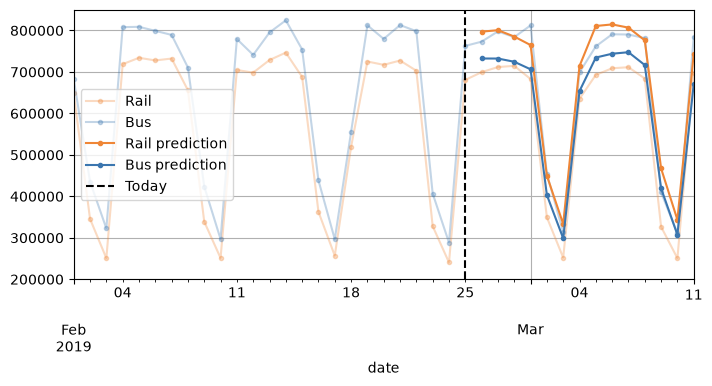

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Y_pred : sortie du modèle au dernier pas, forme (2, 14) = (variable, jour)
Y_pred = Y_pred.detach().cpu().numpy()
print(type(Y_pred), Y_pred.shape)  # <class 'numpy.ndarray'> (2, 14)

today = pd.Timestamp("2019-02-25")  # dernier jour de la fenêtre d'entrée
future = pd.date_range(today + pd.Timedelta(days=1), periods=Y_pred.shape[1])

# L'ordre doit être celui des deux premières colonnes du tenseur d'entrée
Y_pred_bus_s = pd.Series(Y_pred[0] * 1e6, index=future)
Y_pred_rail_s = pd.Series(Y_pred[1] * 1e6, index=future)

recent = df[today - pd.Timedelta(days=24) : future[-1]]  # du 1er février au 11 mars

fig, ax = plt.subplots(figsize=(8, 3.5))
recent["rail"].plot(label="Rail", marker=".", ax=ax, color="#ef8636", alpha=0.3)
recent["bus"].plot(label="Bus", marker=".", ax=ax, color="#3b76af", alpha=0.3)
Y_pred_rail_s.plot(
    grid=True, marker=".", ax=ax, color="#ef8636", label="Rail prediction"
)
Y_pred_bus_s.plot(grid=True, marker=".", ax=ax, color="#3b76af", label="Bus prediction")
ax.axvline(today, color="k", linestyle="--", label="Today")
ax.set_ylim([200_000, 850_000])
ax.legend(loc="center left")
plt.show()

**Exercice 2 : Train a model to predict the next note from a Bach chorales dataset. Then use this model to generate a Bach-like music.**

In [6]:
from IPython.display import Audio

In [7]:
def download_and_extract_bach_data():
    """
    Télécharge et extrait le jeu de données JSB Chorales (chorals de Bach),
    puis renvoie les chemins des fichiers CSV pour chaque split.

    Le téléchargement n'a lieu que si les données ne sont pas déjà présentes
    (vérification de datasets/jsb_chorales/train/chorale_000.csv).

    Entrée
    ------
    Aucune, le lien de téléchargement est hardcodé dans la fonction.

    Sortie
    ------
    csv_list : dict[str, list[Path]]
        Dictionnaire avec les clés "train", "valid" et "test".
        Chaque valeur est la liste triée des chemins vers les fichiers
        chorale_*.csv du split :
            - "train" : 229 fichiers
            - "valid" : 76 fichiers
            - "test"  : 77 fichiers

    Contenu de chaque CSV
    ---------------------
    Un choral de N lignes x 4 colonnes (N varie d'un choral à l'autre).
        - Chaque ligne est un accord, c'est-à-dire un pas de temps.
        - Les 4 colonnes sont les 4 voix (note0 à note3).
        - Chaque valeur est un numéro de note MIDI entre 36 et 81,
          ou 0 pour un silence.
    """

    data_dir = Path("datasets")
    bach_dir = data_dir / "jsb_chorales"

    # On vérifie si le premier CSV existe déjà dans datasets/jsb_chorales/train/
    if not (bach_dir / "train" / "chorale_000.csv").is_file():
        data_dir.mkdir(parents=True, exist_ok=True)
        tarball_path = data_dir / "jsb_chorales.tgz"
        url = "https://homl.info/bach"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as tar:
            tar.extractall(path=data_dir, filter="data")

    csv_list = {
        split: sorted((bach_dir / split).glob("chorale_*.csv"))
        for split in ("train", "valid", "test")
    }
    return csv_list


bach_csv_list = download_and_extract_bach_data()

# Vérification :
for split, files in bach_csv_list.items():
    print(f"{split}: {len(files)} fichiers")

train: 229 fichiers
valid: 76 fichiers
test: 77 fichiers


In [12]:
def load_chorales(filepaths):
    """
    Charge une liste de fichiers CSV de chorals sous forme de tenseurs PyTorch.

    Entrée
    ------
    filepaths : list[Path]
        Chemins des fichiers chorale_*.csv d'un split,
        par exemple bach_datasets_list["train"].

    Sortie
    ------
    chorales : list[torch.Tensor]
        Un tenseur par fichier, dans le même ordre que filepaths.
        Chaque tenseur :
            - forme (N, 4), N étant le nombre de lignes du CSV,
              qui varie d'un choral à l'autre (par exemple 192, 196 ou 228)
            - type torch.long
            - valeurs brutes du CSV : 36 à 81 pour une note MIDI, 0 pour un silence
    """
    chorales = []
    for path in filepaths:
        df = pd.read_csv(path)  # tableau (N, 4)
        chorale = torch.tensor(df.values, dtype=torch.long)
        chorales.append(chorale)
    return chorales


bach_chorales = {split: load_chorales(files) for split, files in bach_csv_list.items()}

# Vérification :
for split, chorales in bach_chorales.items():
    print(
        f"{split}: {len(chorales)} chorals, premier de forme {tuple(chorales[0].shape)}"
    )

train: 229 chorals, premier de forme (192, 4)
valid: 76 chorals, premier de forme (196, 4)
test: 77 chorals, premier de forme (228, 4)


In [ ]:
def play_chorale(chorale, chord_duration=0.25, sample_rate=44100):
    """
    Joue un choral dans le notebook.

    chorale : tenseur ou tableau (N, 4) de notes MIDI brutes (36 à 81, 0 = silence)
    chord_duration : durée d'un accord en secondes
    """
    notes = np.asarray(chorale)  # (N, 4)
    samples = int(sample_rate * chord_duration)  # échantillons par accord

    freqs = 440 * 2 ** ((notes - 69) / 12)  # note MIDI -> fréquence en Hz
    freqs = np.repeat(freqs, samples, axis=0)  # (N * samples, 4)
    is_note = np.repeat(notes != 0, samples, axis=0)  # False pendant les silences

    phase = 2 * np.pi * np.cumsum(freqs, axis=0) / sample_rate
    audio = (np.sin(phase) * is_note).sum(axis=1) / 4  # mélange des 4 voix
    return Audio(audio, rate=sample_rate)


play_chorale(bach_chorales["train"][0])

In [ ]:
class BachDataset(Dataset):
    """
    Dataset PyTorch qui découpe des chorals en fenêtres d'accords consécutifs,
    pour un modèle seq2seq : à chaque pas de temps, la cible est l'accord suivant.

    Paramètres
    ----------
    raw_chorales : list[torch.Tensor]
        Liste des Chorals bruts, chacun de forme (N, 4), par exemple bach_chorales["train"].
    window_length : int, défaut 32
        Nombre d'accords dans une fenêtre d'entrée.
    shift : int, défaut 16
        Décalage, en accords, entre deux fenêtres successives d'un même choral.
        Une petite valeur crée plus de fenêtres, mais très redondantes.
    min_note : int, défaut 36
        Note MIDI la plus basse, utilisée pour convertir les notes en classes.

    Attributs
    ---------
    chorales : list[torch.Tensor]
       Liste des Chorals convertis, chacun de forme (N, 4), avec des valeurs de 0 à 46 :
            - 0 : silence
            - 1 à 46 : notes 36 à 81 (classe = note - 35)
    index : list[tuple[int, int]]
        Liste de toutes les fenêtres valides, sous la forme
        (numéro du choral, ligne de départ).
        Une fenêtre ne chevauche jamais deux chorals.
        Un choral de moins de window_length + 1 lignes ne produit aucune fenêtre.

    __getitem__(idx) renvoie
    ------------------------
    window : torch.Tensor, forme (window_length, 4)
        Accords d'entrée t à t + window_length - 1, valeurs de 0 à 46.
    target : torch.Tensor, forme (window_length, 4)
        Accords t + 1 à t + window_length : la fenêtre décalée d'un accord.
        target[i] est l'accord qui suit window[i].

    Après passage dans un DataLoader : X et y de forme (batch, window_length, 4).

    Conversion inverse vers les notes du CSV : torch.where(x == 0, x, x + 35)
    """

    def __init__(self, raw_chorales, window_length=32, shift=16, min_note=36):
        self.window_length = window_length
        self.chorales = []  # un tenseur (N, 4) par choral, notes converties en classes
        self.index = []  # (numéro du choral, ligne de départ de la fenêtre)

        for chorale_idx, chords in enumerate(raw_chorales):
            # 0 = silence, sinon on ramène les notes 36..81 vers les classes 1..46
            chords = torch.where(chords == 0, chords, chords - min_note + 1)
            self.chorales.append(chords)

            last_start = len(chords) - window_length - 1
            for start in range(0, last_start + 1, shift):
                self.index.append((chorale_idx, start))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        chorale_idx, start = self.index[idx]
        chords = self.chorales[chorale_idx]
        end = start + self.window_length
        window = chords[start:end]  # (32, 4) : accords 0 à 31
        target = chords[start + 1 : end + 1]  # (32, 4) : accords 1 à 32
        return window, target

In [10]:
train_set = BachDataset(bach_chorales["train"])
valid_set = BachDataset(bach_chorales["valid"])
test_set = BachDataset(bach_chorales["test"])

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=32)
test_loader = DataLoader(test_set, batch_size=32)

In [11]:
# Vérification du dataset
# 1. Taille et forme d'un exemple
window, target = train_set[0]
print("Nombre de fenêtres :", len(train_set))
print(
    "Forme fenêtre :",
    tuple(window.shape),
    "| forme cible :",
    tuple(target.shape),
    "| type :",
    window.dtype,
)  # attendu : (32, 4) | (4,) | torch.int64

# 2. Contenu d'un exemple
print("\n4 premiers accords de la fenêtre :\n", window[:4])
print("Cible (classes) :", target.tolist())
print("Cible (notes MIDI) :", torch.where(target == 0, target, target + 35).tolist())

# 3. La cible est-elle bien l'accord suivant ?
chorale_idx, start = train_set.index[0]
chords = train_set.chorales[chorale_idx]
print(
    "\nCible = accord suivant :",
    torch.equal(target, chords[start + train_set.window_length]),
)  # attendu : True

# 4. Plage des valeurs
all_notes = torch.cat(train_set.chorales)
print(
    "Valeurs : min", all_notes.min().item(), "| max", all_notes.max().item()
)  # attendu : 0 et 46

# 5. Répartition des classes
counts = torch.bincount(all_notes.flatten(), minlength=47)
print("Part de silences :", round(counts[0].item() / counts.sum().item(), 3))
print("Classes jamais vues :", (counts == 0).nonzero().flatten().tolist())

# 6. Fenêtres par choral
chorale_ids = torch.tensor([c for c, _ in train_set.index])
windows_per_chorale = torch.bincount(chorale_ids, minlength=len(train_set.chorales))
print(
    "Chorals utilisés :",
    (windows_per_chorale > 0).sum().item(),
    "/",
    len(train_set.chorales),
)
print(
    "Fenêtres par choral : min",
    windows_per_chorale.min().item(),
    "| max",
    windows_per_chorale.max().item(),
)

Nombre de fenêtres : 3111
Forme fenêtre : (32, 4) | forme cible : (32, 4) | type : torch.int64

4 premiers accords de la fenêtre :
 tensor([[39, 35, 30, 23],
        [39, 35, 30, 23],
        [39, 35, 30, 23],
        [39, 35, 30, 23]])
Cible (classes) : [[39, 35, 30, 23], [39, 35, 30, 23], [39, 35, 30, 23], [40, 35, 23, 20], [40, 35, 23, 20], [40, 35, 25, 20], [40, 35, 25, 20], [42, 34, 27, 15], [42, 34, 27, 15], [42, 34, 27, 15], [42, 34, 27, 15], [42, 35, 27, 20], [42, 35, 27, 20], [42, 34, 27, 20], [42, 34, 27, 20], [40, 32, 28, 13], [40, 32, 28, 13], [40, 34, 28, 13], [40, 34, 28, 13], [39, 35, 30, 11], [39, 35, 30, 11], [39, 35, 30, 11], [39, 35, 30, 11], [37, 34, 30, 18], [37, 34, 30, 18], [37, 34, 30, 18], [37, 34, 30, 18], [37, 34, 30, 18], [37, 34, 30, 18], [37, 34, 30, 18], [37, 34, 30, 18], [39, 35, 30, 11]]
Cible (notes MIDI) : [[74, 70, 65, 58], [74, 70, 65, 58], [74, 70, 65, 58], [75, 70, 58, 55], [75, 70, 58, 55], [75, 70, 60, 55], [75, 70, 60, 55], [77, 69, 62, 50], [7

In [ ]:
import torch.nn.functional as F


class BachRNN(nn.Module):
    """
    Modèle récurrent seq2seq : à chaque pas de temps, prédit l'accord suivant.

    Paramètres
    ----------
    n_classes : int, défaut 47
        Nombre de classes par note (0 = silence, 1 à 46 = notes).
    n_voices : int, défaut 4
        Nombre de notes par accord.
    hidden_size : int, défaut 128
        Taille de l'état caché du GRU.
    num_layers : int, défaut 2
        Nombre de couches GRU empilées.
    dropout : float, défaut 0.2
        Dropout entre les couches GRU.

    Entrée
    ------
    X : torch.Tensor, forme (batch, T, 4), type torch.long
        Accords d'entrée, valeurs de 0 à 46.

    Sortie
    ------
    logits : torch.Tensor, forme (batch, 47, T, 4)
        Scores des 47 classes pour chaque voix de l'accord suivant, à chaque pas.
        Format attendu par nn.CrossEntropyLoss avec une cible y de forme (batch, T, 4).
    """

    def __init__(
        self, n_classes=47, n_voices=4, hidden_size=128, num_layers=2, dropout=0.2
    ):
        super().__init__()
        self.n_classes = n_classes
        self.n_voices = n_voices
        self.gru = nn.GRU(
            input_size=n_voices * n_classes,  # 4 notes en one-hot : 4 x 47 = 188
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout,
        )
        self.head = nn.Linear(hidden_size, n_voices * n_classes)

    def forward(self, X):
        batch, T, _ = X.shape

        # 1. Encodage one-hot : (batch, T, 4) -> (batch, T, 4, 47) -> (batch, T, 188)
        Z = F.one_hot(X, num_classes=self.n_classes).float()
        Z = Z.flatten(start_dim=2)

        # 2. Lecture de la séquence : une sortie par pas de temps
        outputs, _ = self.gru(Z)  # (batch, T, hidden_size)

        # 3. Prédiction de l'accord suivant à chaque pas
        logits = self.head(outputs)  # (batch, T, 188)
        logits = logits.view(batch, T, self.n_classes, self.n_voices)
        return logits.permute(0, 2, 1, 3)  # (batch, 47, T, 4)